# Laboratorio guidato: Regole di associazione con Apriori e FP-Growth

**Dataset:** Groceries  
**Domanda guida:** quali prodotti vengono acquistati insieme e quali associazioni vale la pena approfondire?

> **Prima di iniziare:** metti `groceries.csv` nella stessa cartella del notebook (oppure in `../data/`). La cella di caricamento cerca il file in entrambe le posizioni; se il tuo percorso è diverso, modifica `CSV_CANDIDATI`.

## Obiettivi del laboratorio

- Capire che cosa rappresentano support, confidence e lift.
- Osservare come cambiano itemset e regole modificando le soglie.
- Confrontare le classifiche per support, confidence e lift.
- Motivare una scelta commerciale senza confondere associazione e causalità.

## Prima della pratica: le tre metriche

Consideriamo una regola della forma `A → B`, dove `A` è l'antecedente e `B` il conseguente.

| Metrica | Formula | Domanda a cui risponde |
|---|---|---|
| **Support** | transazioni che contengono sia A sia B / tutte le transazioni | Quanto spesso si verifica questa combinazione? |
| **Confidence** | Support(A ∪ B) / Support(A) | Quale percentuale di chi compra A prende anche B? |
| **Lift** | Confidence(A → B) / Support(B) | La regola è utile o B si vende comunque da solo? |

Interpretazione standard del lift:
- `lift > 1`: associazione positiva rispetto all'indipendenza;
- `lift = 1`: indipendenza statistica;
- `lift < 1`: associazione negativa rispetto all'indipendenza.

**Proprietà utile:** support e lift sono **simmetrici** (valgono uguali per `A → B` e `B → A`, con A e B itemset qualsiasi), perché il lift si può scrivere come Support(A ∪ B) / (Support(A) · Support(B)). La confidence invece **non** è simmetrica, perché cambia il denominatore.

**Attenzione:** le metriche non sono intercambiabili. Una confidence elevata, da sola, non dimostra che l'associazione sia insolita; un lift elevato non dimostra una relazione causale. Le tre metriche sono su scale diverse, quindi "bilanciata" è una valutazione qualitativa, non una formula standard.

## 1. Caricamento dataset

Nel dataset Groceries ogni riga rappresenta una transazione. I prodotti della stessa transazione sono separati da virgole; le righe possono quindi contenere numeri diversi di prodotti. Per questo leggiamo il file riga per riga, invece di interpretarlo come una tabella rettangolare standard.

In [ ]:
# ─────────────────────────────────────────────────────────────
# 1. CARICAMENTO DATASET DA CSV
import os
import time
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

CSV_CANDIDATI = ["groceries.csv", "../data/groceries.csv"]  # Modifica se necessario

CSV_PATH = next((p for p in CSV_CANDIDATI if os.path.exists(p)), None)
if CSV_PATH is None:
    raise FileNotFoundError(
        f"groceries.csv non trovato. Percorsi provati: {CSV_CANDIDATI}. "
        "Copia il file accanto al notebook o aggiorna CSV_CANDIDATI."
    )

with open(CSV_PATH, "r", encoding="utf-8-sig") as f:
    transazioni = []
    for riga in f:
        if riga.strip():
            prodotti = riga.strip().split(",")
            prodotti = [p.strip() for p in prodotti if p.strip()]
            transazioni.append(prodotti)

assert len(transazioni) > 0, "Nessuna transazione letta: controlla il file."

print(f"File letto da: {CSV_PATH}")
print("Prime 5 transazioni:")
for i, transazione in enumerate(transazioni[:5], start=1):
    print(f"{i}: {transazione}")

print("\n" + "=" * 60)
print("DATASET: {} transazioni, prodotti unici: {}".format(
    len(transazioni),
    len({p for t in transazioni for p in t})
))
print("=" * 60)

File letto da: ../data/groceries.csv
Prime 5 transazioni:
1: ['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']
2: ['tropical fruit', 'yogurt', 'coffee']
3: ['whole milk']
4: ['pip fruit', 'yogurt', 'cream cheese', 'meat spreads']
5: ['other vegetables', 'whole milk', 'condensed milk', 'long life bakery product']

DATASET: 9835 transazioni, prodotti unici: 169


### Domande di comprensione

1. Che cosa rappresenta una transazione in questo dataset?
2. Perché non possiamo assumere che tutte le righe abbiano lo stesso numero di prodotti?
3. Perché il numero totale di transazioni è importante per interpretare il support?

## 2. Encoding delle transazioni

`TransactionEncoder` trasforma la lista di liste in una matrice booleana: ogni riga è una transazione, ogni colonna è un prodotto e `True` indica che il prodotto è presente nello scontrino.

Dopo l'encoding calcoliamo anche la **densità** della matrice (quota di celle `True`) e il numero totale di transazioni `N`, che useremo per convertire i support in numero di scontrini.

In [69]:
# ─────────────────────────────────────────────────────────────
# 2. ENCODING DELLE TRANSAZIONI
te = TransactionEncoder()
te_array = te.fit_transform(transazioni)
df = pd.DataFrame(te_array, columns=te.columns_)
N = len(df)

print("Dimensioni della matrice transazioni:", df.shape)
print(f"Densità della matrice (quota di True): {df.values.mean():.3%}")
print(f"Prodotti per scontrino: media = {df.sum(axis=1).mean():.1f}, massimo = {df.sum(axis=1).max()}")
print("\nPrime 5 righe e prime 8 colonne:")
print(df.iloc[:5, :8].to_string())

Dimensioni della matrice transazioni: (9835, 169)
Densità della matrice (quota di True): 2.609%
Prodotti per scontrino: media = 4.4, massimo = 32

Prime 5 righe e prime 8 colonne:
   Instant food products  UHT-milk  abrasive cleaner  artif. sweetener  baby cosmetics  baby food   bags  baking powder
0                  False     False             False             False           False      False  False          False
1                  False     False             False             False           False      False  False          False
2                  False     False             False             False           False      False  False          False
3                  False     False             False             False           False      False  False          False
4                  False     False             False             False           False      False  False          False


### Domande di comprensione

- Che cosa rappresenta il valore `True` nella matrice?
- La matrice è quasi tutta `False`: che cosa implica per le soglie di support che possiamo permetterci?
- Perché gli algoritmi lavorano su questa rappresentazione invece che sulle liste testuali originali?

## 3. Parametri iniziali

Partiamo da una soglia di supporto dell'1%, una confidence minima del 30% e un lift minimo pari a 1. Le soglie verranno cambiate negli esperimenti successivi.

- `MIN_SUPPORT`: esclude gli itemset troppo rari.
- `MIN_CONFIDENCE`: seleziona regole con confidence almeno pari alla soglia.
- `MIN_LIFT`: nella selezione finale conserva solo le regole con lift almeno pari alla soglia.

La cella definisce anche due piccole funzioni di servizio, per evitare di stampare tabelle lunghissime:
- `genera_regole(...)` chiama `association_rules` (compatibile con le diverse versioni di mlxtend);
- `mostra_regole(...)` stampa le prime `n` regole in forma leggibile, con anche il **numero di scontrini** che le sostengono.

In [70]:
# ─────────────────────────────────────────────────────────────
# 3. PARAMETRI DEFINITI DALL'UTENTE E FUNZIONI DI SERVIZIO
MIN_SUPPORT = 0.01
MIN_CONFIDENCE = 0.30
MIN_LIFT = 1.0

print(f"MIN_SUPPORT    = {MIN_SUPPORT:.3f}")
print(f"MIN_CONFIDENCE = {MIN_CONFIDENCE:.2f}")
print(f"MIN_LIFT       = {MIN_LIFT:.2f}")


def genera_regole(freq, min_confidence):
    """Genera le regole dagli itemset frequenti (compatibile con più versioni di mlxtend)."""
    try:
        return association_rules(
            freq, num_itemsets=N, metric="confidence", min_threshold=min_confidence
        )
    except TypeError:  # versioni più vecchie senza il parametro num_itemsets
        return association_rules(
            freq, metric="confidence", min_threshold=min_confidence
        )


def mostra_regole(regole, n=10, ordina="lift"):
    """Stampa le prime n regole ordinate per la metrica scelta."""
    if regole.empty:
        print("(nessuna regola)")
        return
    tab = regole.sort_values(ordina, ascending=False).head(n).copy()
    tab["regola"] = (
        tab["antecedents"].apply(lambda s: ", ".join(sorted(s)))
        + " → "
        + tab["consequents"].apply(lambda s: ", ".join(sorted(s)))
    )
    tab["n_scontrini"] = (tab["support"] * N).round().astype(int)
    print(tab[["regola", "n_scontrini", "support", "confidence", "lift"]]
          .round(3).to_string(index=False))

MIN_SUPPORT    = 0.010
MIN_CONFIDENCE = 0.30
MIN_LIFT       = 1.00


## 4. Algoritmo Apriori

Apriori genera candidati a livelli e usa il principio secondo cui, se un itemset è infrequente, anche i suoi superset non possono essere frequenti. Le celle seguenti contano gli itemset frequenti e mostrano le prime regole che superano le soglie impostate (le tabelle complete sono lunghe: si possono vedere cambiando `n`).

In [82]:
# ─────────────────────────────────────────────────────────────
# 4. ALGORITMO APRIORI
print("─" * 60)
print("APRIORI")
print("─" * 60)

freq_apriori = apriori(
    df,
    min_support=MIN_SUPPORT,
    use_colnames=True
).sort_values("support", ascending=False)

print(f"Itemset frequenti trovati (Apriori): {len(freq_apriori)}")
print("\nPer lunghezza dell'itemset:")
print(freq_apriori["itemsets"].apply(len).value_counts().sort_index().to_string())
print("\nPrimi 10 itemset per support:")
print(freq_apriori.head(10).to_string(index=False))

────────────────────────────────────────────────────────────
APRIORI
────────────────────────────────────────────────────────────
Itemset frequenti trovati (Apriori): 333

Per lunghezza dell'itemset:
itemsets
1     88
2    213
3     32

Primi 10 itemset per support:
 support                      itemsets
0.255516       frozenset({whole milk})
0.193493 frozenset({other vegetables})
0.183935       frozenset({rolls/buns})
0.174377             frozenset({soda})
0.139502           frozenset({yogurt})
0.110524    frozenset({bottled water})
0.108998  frozenset({root vegetables})
0.104931   frozenset({tropical fruit})
0.098526    frozenset({shopping bags})
0.093950          frozenset({sausage})


In [72]:
regole_apriori_grezze = genera_regole(freq_apriori, MIN_CONFIDENCE)
print(f"Regole con confidence >= {MIN_CONFIDENCE:.2f}: {len(regole_apriori_grezze)}")

regole_apriori = regole_apriori_grezze[
    regole_apriori_grezze["lift"] >= MIN_LIFT
].sort_values("lift", ascending=False).copy()
print(f"Regole con lift >= {MIN_LIFT:.2f}:        {len(regole_apriori)}")

print("\nPrime 10 regole per lift:")
mostra_regole(regole_apriori, n=10, ordina="lift")

Regole con confidence >= 0.30: 125
Regole con lift >= 1.00:        125

Prime 10 regole per lift:
                                            regola  n_scontrini  support  confidence  lift
  citrus fruit, other vegetables → root vegetables          102    0.010       0.359 3.295
other vegetables, tropical fruit → root vegetables          121    0.012       0.343 3.145
                            beef → root vegetables          171    0.017       0.331 3.040
  citrus fruit, root vegetables → other vegetables          102    0.010       0.586 3.030
root vegetables, tropical fruit → other vegetables          121    0.012       0.585 3.021
    other vegetables, whole milk → root vegetables          228    0.023       0.310 2.842
                         curd, whole milk → yogurt           99    0.010       0.385 2.761
    rolls/buns, root vegetables → other vegetables          120    0.012       0.502 2.595
        root vegetables, yogurt → other vegetables          127    0.013       0.50

### Discussione: Apriori

- Quanti itemset frequenti ha trovato l'algoritmo? Quanti sono di lunghezza 1, 2, 3?
- Quante regole rimangono dopo il filtro sulla confidence? E dopo il filtro sul lift?
- Perché conviene esaminare una regola usando tutte e tre le metriche, invece di guardare solo la confidence?

## 5. Algoritmo FP-Growth

FP-Growth costruisce una struttura compatta chiamata FP-Tree e non genera esplicitamente l'intero insieme dei candidati come Apriori. Con gli stessi dati e parametri deve produrre gli stessi itemset frequenti.

In [83]:
# ─────────────────────────────────────────────────────────────
# 5. ALGORITMO FP-GROWTH
print("─" * 60)
print("FP-GROWTH")
print("─" * 60)

freq_fpgrowth = fpgrowth(
    df,
    min_support=MIN_SUPPORT,
    use_colnames=True
).sort_values("support", ascending=False)

print(f"Itemset frequenti trovati (FP-Growth): {len(freq_fpgrowth)}")
print("\nPrimi 10 itemset per support:")
print(freq_fpgrowth.head(10).to_string(index=False))

────────────────────────────────────────────────────────────
FP-GROWTH
────────────────────────────────────────────────────────────
Itemset frequenti trovati (FP-Growth): 333

Primi 10 itemset per support:
 support                      itemsets
0.255516       frozenset({whole milk})
0.193493 frozenset({other vegetables})
0.183935       frozenset({rolls/buns})
0.174377             frozenset({soda})
0.139502           frozenset({yogurt})
0.110524    frozenset({bottled water})
0.108998  frozenset({root vegetables})
0.104931   frozenset({tropical fruit})
0.098526    frozenset({shopping bags})
0.093950          frozenset({sausage})


In [84]:
regole_fpgrowth_grezze = genera_regole(freq_fpgrowth, MIN_CONFIDENCE)
print(f"Regole con confidence >= {MIN_CONFIDENCE:.2f}: {len(regole_fpgrowth_grezze)}")

regole_fpgrowth = regole_fpgrowth_grezze[
    regole_fpgrowth_grezze["lift"] >= MIN_LIFT
].sort_values("lift", ascending=False).copy()
print(f"Regole con lift >= {MIN_LIFT:.2f}:        {len(regole_fpgrowth)}")

print("\nPrime 10 regole per lift:")
mostra_regole(regole_fpgrowth, n=10, ordina="lift")

Regole con confidence >= 0.30: 125
Regole con lift >= 1.00:        125

Prime 10 regole per lift:
                                            regola  n_scontrini  support  confidence  lift
  citrus fruit, other vegetables → root vegetables          102    0.010       0.359 3.295
other vegetables, tropical fruit → root vegetables          121    0.012       0.343 3.145
                            beef → root vegetables          171    0.017       0.331 3.040
  citrus fruit, root vegetables → other vegetables          102    0.010       0.586 3.030
root vegetables, tropical fruit → other vegetables          121    0.012       0.585 3.021
    other vegetables, whole milk → root vegetables          228    0.023       0.310 2.842
                         curd, whole milk → yogurt           99    0.010       0.385 2.761
    rolls/buns, root vegetables → other vegetables          120    0.012       0.502 2.595
        root vegetables, yogurt → other vegetables          127    0.013       0.50

### Discussione: FP-Growth

1. Il numero di itemset trovati coincide con quello di Apriori?
2. A parità di parametri, ti aspetti regole diverse oppure gli stessi risultati?
3. Il confronto della **correttezza** dei risultati è diverso dal confronto dei **tempi di esecuzione**: li confronteremo entrambi nella prossima sezione.

## 6. Confronto tra i due algoritmi

Il confronto controlla sia gli itemset frequenti sia le regole dopo l'applicazione dei filtri. Poi misuriamo anche i **tempi**.

In [85]:
# ─────────────────────────────────────────────────────────────
# 6a. CONFRONTO DEI RISULTATI
set_apriori = set(map(frozenset, freq_apriori["itemsets"]))
set_fpgrowth = set(map(frozenset, freq_fpgrowth["itemsets"]))
print("Itemset identici tra Apriori e FP-Growth? →", set_apriori == set_fpgrowth)

firme_apriori = {
    (frozenset(row["antecedents"]), frozenset(row["consequents"]))
    for _, row in regole_apriori.iterrows()
}
firme_fpgrowth = {
    (frozenset(row["antecedents"]), frozenset(row["consequents"]))
    for _, row in regole_fpgrowth.iterrows()
}
print("Regole identiche dopo i filtri? →", firme_apriori == firme_fpgrowth)

Itemset identici tra Apriori e FP-Growth? → True
Regole identiche dopo i filtri? → True


In [88]:
# ─────────────────────────────────────────────────────────────
# 6b. CONFRONTO DEI TEMPI
# Misuriamo il tempo migliore su 3 ripetizioni, abbassando progressivamente il supporto.
# ATTENZIONE: con supporti molto bassi il numero di itemset cresce rapidamente.
def tempo_migliore(funzione, supporto, ripetizioni=3):
    tempi = []
    for _ in range(ripetizioni):
        t0 = time.perf_counter()
        risultato = funzione(df, min_support=supporto, use_colnames=True)
        tempi.append(time.perf_counter() - t0)
    return min(tempi), len(risultato)

righe_tempi = []
for supporto in [0.01, 0.005, 0.0025]:
    t_ap, n_ap = tempo_migliore(apriori, supporto)
    t_fp, n_fp = tempo_migliore(fpgrowth, supporto)
    righe_tempi.append({
        "supporto_minimo": supporto,
        "itemset": n_ap,
        "tempo_apriori_s": round(t_ap, 3),
        "tempo_fpgrowth_s": round(t_fp, 3),
        "rapporto_apriori/fpgrowth": round(t_ap / t_fp, 2),
    })

print(pd.DataFrame(righe_tempi).to_string(index=False))

 supporto_minimo  itemset  tempo_apriori_s  tempo_fpgrowth_s  rapporto_apriori/fpgrowth
          0.0100      333            0.082             0.145                       0.57
          0.0050     1001            0.250             0.199                       1.26
          0.0025     2960            0.675             0.392                       1.72


### Come leggere i tempi

I tempi dipendono dalla macchina e dalla versione di mlxtend, quindi **annota i tuoi valori** invece di cercare numeri "giusti". Quello che conta è la tendenza:

- con supporto 0,01 i due algoritmi sono tipicamente vicini, perché gli itemset sono pochi;
- abbassando il supporto il numero di itemset cresce e le differenze di tempo tendono a diventare più evidenti.

**Domande:** a parità di risultati, quando ha senso preferire FP-Growth? Il fatto che un algoritmo sia più veloce lo rende "più corretto"?

## 7. Visualizzazione: support vs confidence

Ogni punto rappresenta una regola. La posizione mostra support e confidence; il colore rappresenta il lift. Il grafico aiuta a individuare regole relativamente frequenti e con confidence elevata, ma i numeri devono comunque essere letti insieme.

La scala di colore parte da `MIN_LIFT`, perché tutte le regole mostrate hanno lift almeno pari a quella soglia.

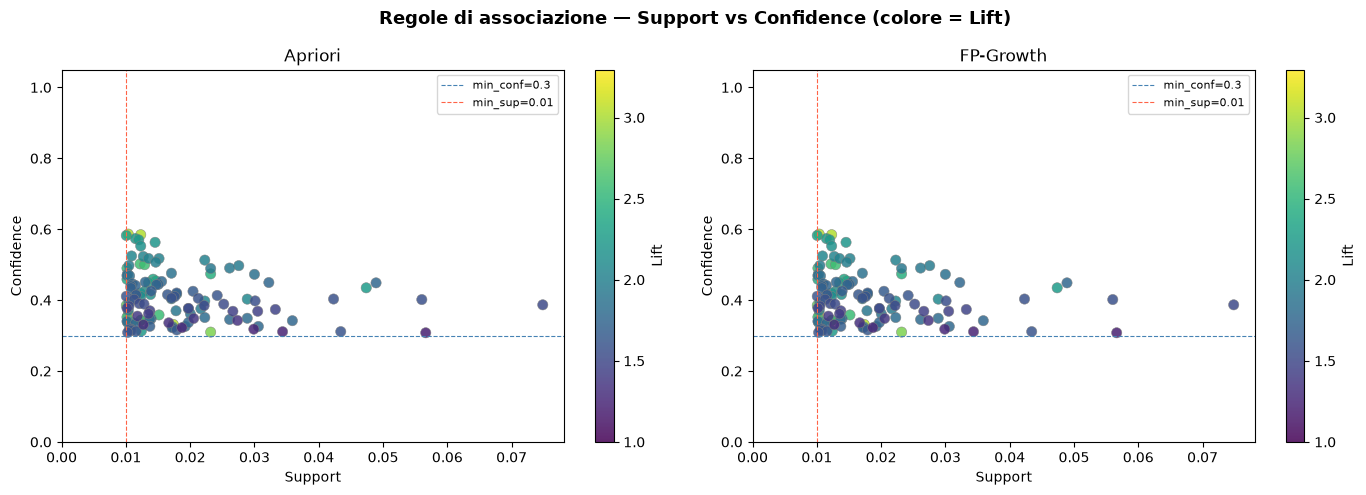

In [87]:
# ─────────────────────────────────────────────────────────────
# 7. VISUALIZZAZIONE (scatter support vs confidence)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Regole di associazione — Support vs Confidence (colore = Lift)",
             fontsize=13, fontweight="bold")

for ax, (regole, titolo) in zip(
    axes,
    [(regole_apriori, "Apriori"), (regole_fpgrowth, "FP-Growth")]
):
    if regole.empty:
        ax.set_title(f"{titolo} — nessuna regola dopo i filtri")
        continue
    sc = ax.scatter(
        regole["support"], regole["confidence"],
        c=regole["lift"], cmap="viridis", vmin=MIN_LIFT,
        s=55, edgecolors="grey", linewidths=0.4, alpha=0.85
    )
    fig.colorbar(sc, ax=ax, label="Lift")
    ax.set_title(titolo)
    ax.set_xlabel("Support")
    ax.set_ylabel("Confidence")
    ax.set_xlim(left=0)
    ax.set_ylim(0, 1.05)
    ax.axhline(MIN_CONFIDENCE, color="steelblue", linestyle="--",
               linewidth=0.8, label=f"min_conf={MIN_CONFIDENCE}")
    ax.axvline(MIN_SUPPORT, color="tomato", linestyle="--",
               linewidth=0.8, label=f"min_sup={MIN_SUPPORT}")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("groceries_association_rules_plot.png", dpi=150, bbox_inches="tight")
plt.show()